# An earthquake source from regional elastic waves

This review actively reconstructs the complete signed moment tensor and discrete source depth of the 16 July 2019 California event. All eight stations in the author's shipped acquisition are used. The observations are real displacement records. Neither a reconstructed source tensor nor an earthquake catalogue solution is physical ground truth.

The six sections connect the measured waveforms, calibrated radiation physics, fresh inversion, independent original-code comparison, physical diagnostics, and sensitivity experiments. Historical plots from the paper are context, not measurements of this acquisition. All graphs labelled **fresh** are computed by the cleaned modules in this execution.

In [1]:
import os,sys,time,json
from pathlib import Path
root=Path.cwd()
if not (root/'src').is_dir():
    root=root.parent
assert (root/'data/raw_data.npz').is_file()
os.chdir(root);sys.path.insert(0,str(root))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.preprocessing import load_data,window_waveforms,distance_weights,STATIONS
from src.physics_model import design_matrix,forward,tensor_to_coefficients
from src.solvers import solve,variance_reduction
from src.visualization import plot_tensor_and_radiation,plot_waveforms,tensor_relative_error
from src.main import main
started=time.perf_counter()
data=load_data();observed=window_waveforms(data['waveforms'])
original=np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False)
original_dev=np.load('notebooks/reference_outputs/upstream_deviatoric.npz',allow_pickle=False)
print('Measured records:',data['waveforms'].shape,'native dtype:',data['waveforms'].dtype)
print('Fundamental Green calibration:',data['fundamental_greens'].shape)
print('No ground-truth source tensor is supplied.')

print('Kernel executable:',sys.executable,'NumPy:',np.__version__)


Measured records: (8, 3, 231) native dtype: float32
Fundamental Green calibration: (3, 8, 10, 150)
No ground-truth source tensor is supplied.
Kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6


## 1. Observations and acquisition geometry

Instrument responses were removed before these records were archived. All traces have a common 0.02–0.05 Hz bandpass and 1 s sampling interval. The 231-sample records begin 30 s before the origin. Station-specific starts of 31 or 32 samples align the 150-sample inverse windows with the independent Green calibration. This registration is fixed; it is not re-estimated using a hidden source.

The station azimuths are uneven, so similar waveform fit can coexist with source-tensor sensitivity. Distances, angular coverage and per-component amplitudes are visible below.

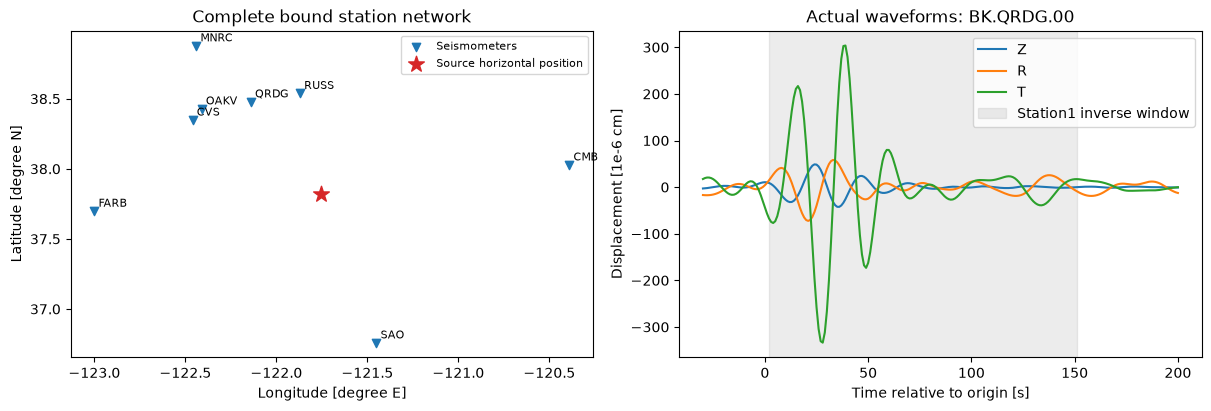

In [2]:
fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
coords=data['station_coordinates']
axs[0].scatter(coords[:,0],coords[:,1],marker='v',color='C0',label='Seismometers')
axs[0].scatter([-121.7568],[37.8187],marker='*',s=140,color='C3',label='Source horizontal position')
for i,name in enumerate(STATIONS):axs[0].annotate(name.split('.')[1],coords[i],xytext=(3,3),textcoords='offset points',fontsize=8)
axs[0].set(xlabel='Longitude [degree E]',ylabel='Latitude [degree N]',title='Complete bound station network');axs[0].legend(fontsize=8)
timeaxis=np.arange(231)-30
for j,c in enumerate('ZRT'):axs[1].plot(timeaxis,data['waveforms'][0,j]*1e6,label=c)
axs[1].axvspan(2,151,color='grey',alpha=.15,label='Station1 inverse window')
axs[1].set(xlabel='Time relative to origin [s]',ylabel='Displacement [1e-6 cm]',title=f'Actual waveforms: {STATIONS[0]}');axs[1].legend()
plt.show()


## 2. Radiation model and physical unknown

The symmetric north-east-down moment tensor $M$ has six signed components in Nm. The dimensionless coefficient vector is $a=(M_{NN},M_{NE},M_{ND},M_{EE},M_{ED},M_{DD})/(10^{13}\,\mathrm{Nm})$. At each candidate depth, calibrated fundamental-fault waveforms and station azimuths form the explicit operator $G$ with measurement equation $d=Ga+\epsilon$. Displacement $d$ is in cm; rows order station, then Z/R/T component, then time.

For source-to-station azimuth $\alpha$, the four vertical/radial radiation amplitudes are

$$A=\frac{1}{2}(a_1-a_4)\cos(2\alpha)+a_2\sin(2\alpha),\qquad B=a_3\cos\alpha+a_5\sin\alpha,$$
$$C=-0.166667(a_1+a_4)+0.33333a_6,\qquad I=0.33333(a_1+a_4+a_6).$$

For either vertical or radial component $q$, $u_q=AqSS+BqDS+CqDD+IqEX$. The transverse response is

$$u_T=[\frac{1}{2}(a_1-a_4)\sin(2\alpha)-a_2\cos(2\alpha)]TSS+[a_3\sin\alpha-a_5\cos\alpha]TDS.$$

Each capital Green symbol names a supplied fundamental-fault trace. These equations preserve the source signs and precision. The complete source contains the isotropic part $\mathrm{tr}(M)I_3/3$, where $I_3$ is the three-dimensional identity, and a trace-free part. Omitting the explosion Green response changes the physical inverse. Decimal mixing coefficients 0.166667 and 0.33333 approximate rational constants and create the documented tiny radial/vertical isotropic leakage; transverse isotropic radiation remains exactly zero.

The plots show supplied source-independent calibration, not responses synthesized using a known target. It encodes a fixed layered Earth model, which need not perfectly describe the real crust.

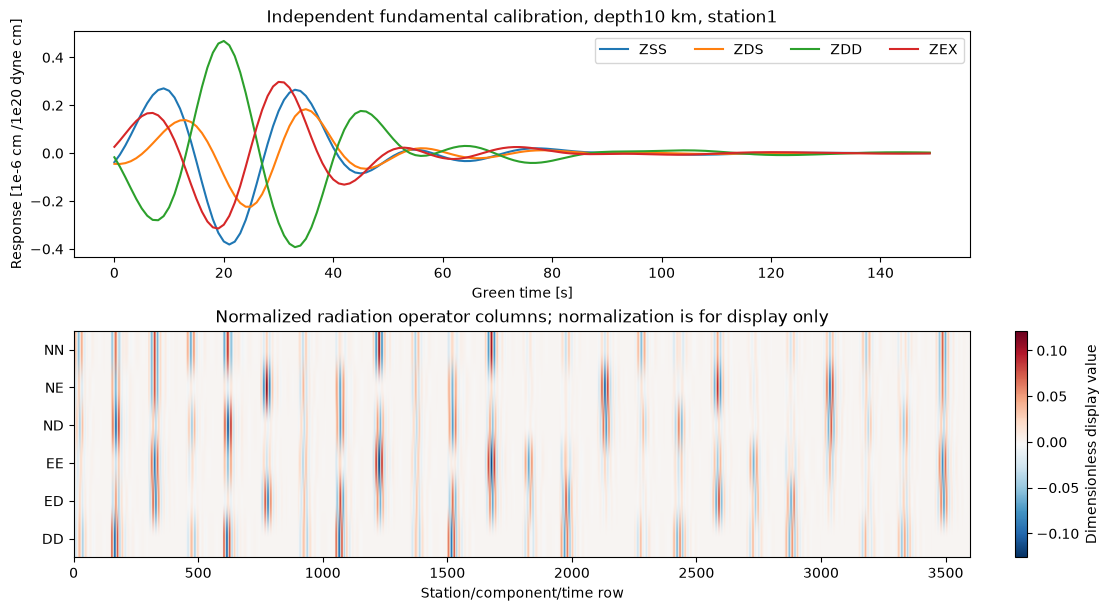

In [3]:
fig,axs=plt.subplots(2,1,figsize=(11,6),constrained_layout=True)
for k,name in enumerate(['ZSS','ZDS','ZDD','ZEX']):axs[0].plot(np.arange(150),data['fundamental_greens'][0,0,k]*1e6,label=name)
axs[0].set(xlabel='Green time [s]',ylabel='Response [1e-6 cm /1e20 dyne cm]',title='Independent fundamental calibration, depth10 km, station1');axs[0].legend(ncol=4)
G=design_matrix(data['fundamental_greens'][0],data['station_azimuth'])
column_norm=np.linalg.norm(G,axis=0)
im=axs[1].imshow((G/column_norm).T,aspect='auto',cmap='RdBu_r',extent=(0,G.shape[0],5.5,-.5))
axs[1].set_yticks(range(6),['NN','NE','ND','EE','ED','DD']);axs[1].set(xlabel='Station/component/time row',title='Normalized radiation operator columns; normalization is for display only')
fig.colorbar(im,ax=axs[1],label='Dimensionless display value');plt.show()


## 3. Fresh reconstruction and waveform fit

At each depth, minimize the objective

$$J(a)=\frac{1}{2}(d-Ga)^T W(d-Ga).$$

Here $W$ is diagonal, containing station distance divided by the minimum distance, repeated across all component/time samples. Its entries are objective weights. The solution evaluates the normal equations

$$(G^T W G)a=G^T Wd.$$

This closed-form linear inverse needs no iterative initialization or hidden checkpoint. Select the depth giving the largest distance-weighted variance reduction,

$$\mathrm{VR}=100\left[1-\frac{\sum w(d-Ga)^2}{\sum wd^2}\right].$$

All sums range over station, component and time, and $w$ denotes the corresponding diagonal weight. The next cell runs the standard entry point and writes a new submission. Every station and component is plotted against its freshly computed prediction without per-trace amplitude fitting.

Fresh full inverse seconds: 0.0027356999926269054
Candidate depths [km]: [10. 12. 20.]
Fresh weighted variance reduction [%]: [74.46893184 73.86477094 70.67933776]
Selected depth [km]: 10.0
Signed tensor [Nm]:
 [[-2.83618419e+15 -1.06666403e+15  1.03335516e+15]
 [-1.06666403e+15  3.45784476e+15  1.06620935e+15]
 [ 1.03335516e+15  1.06620935e+15 -3.03666821e+14]]


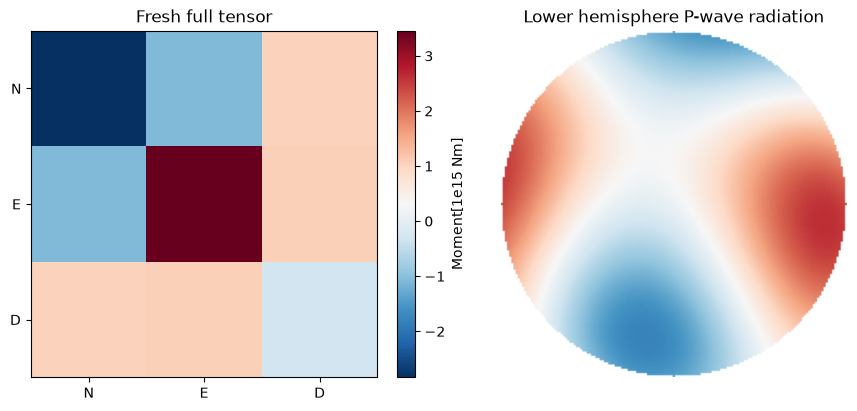

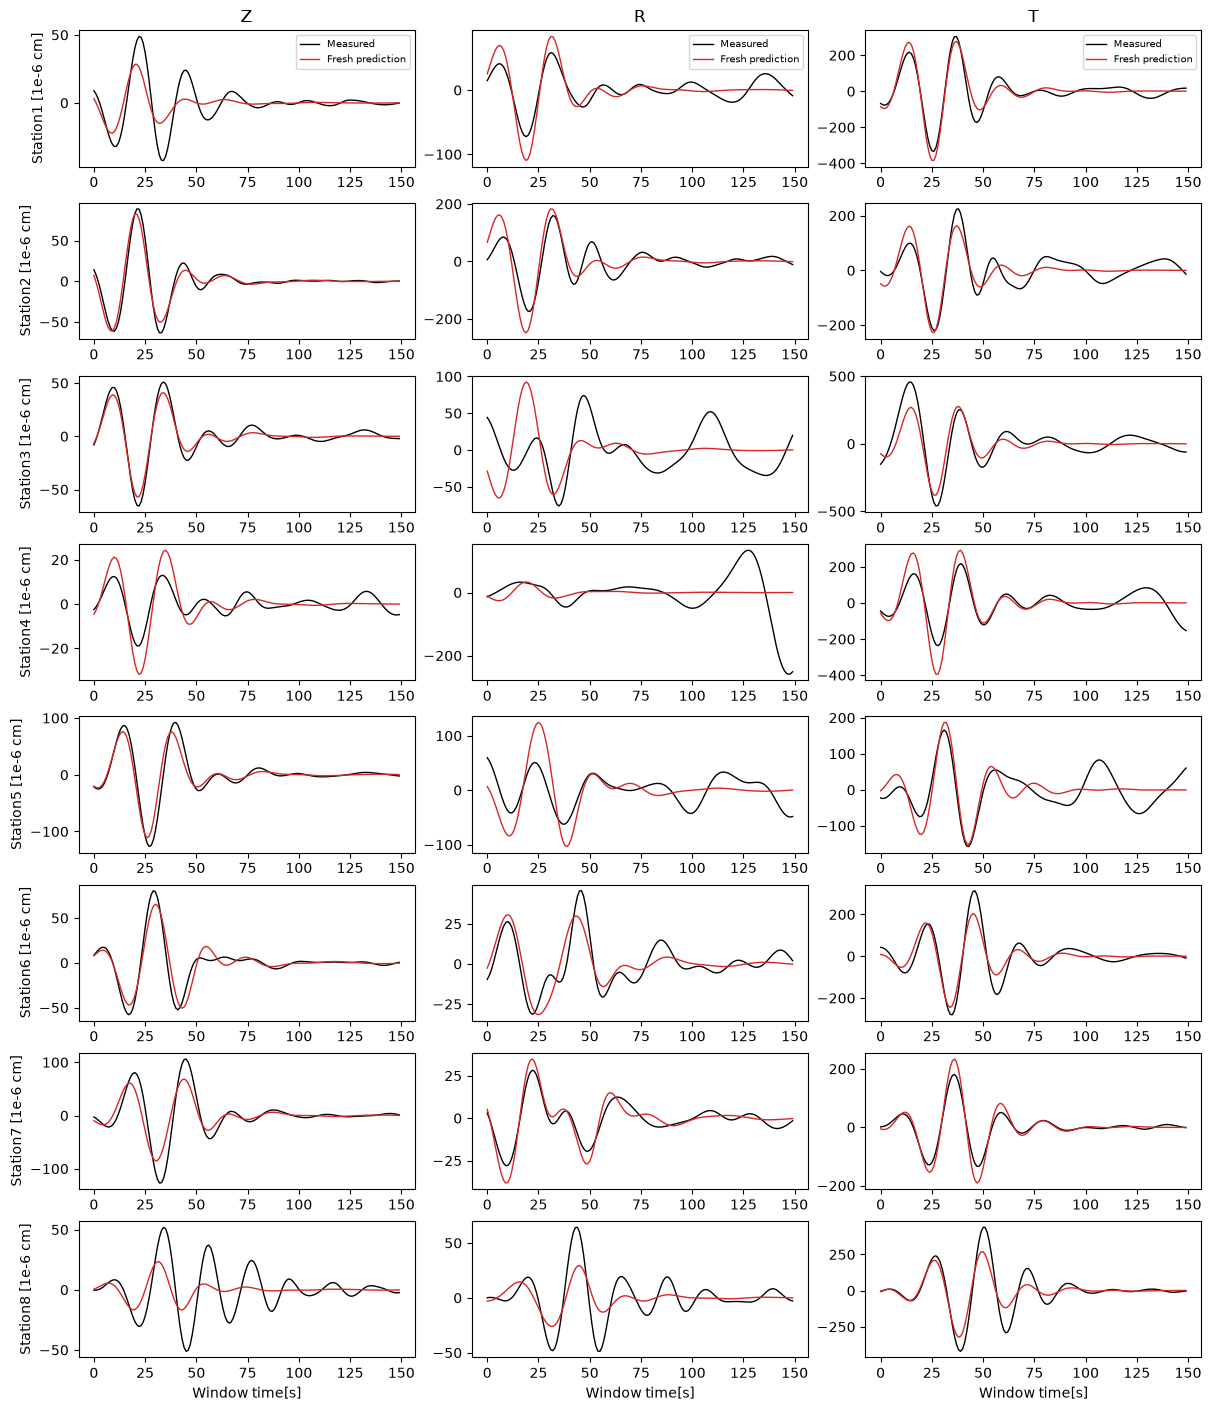

In [4]:
tic=time.perf_counter();fresh=main();runtime=time.perf_counter()-tic
best=fresh['best'];tensor=fresh['reconstruction'][0];prediction=fresh['predictions'][best]
print('Fresh full inverse seconds:',runtime)
print('Candidate depths [km]:',fresh['depths'])
print('Fresh weighted variance reduction [%]:',fresh['variance_reduction'])
print('Selected depth [km]:',fresh['source_depth'].item())
print('Signed tensor [Nm]:\n',tensor)
plot_tensor_and_radiation(tensor);plt.show()
plot_waveforms(observed,prediction);plt.show()


## 4. Independent reproduction and scientific comparison

The original MTtime implementation was executed independently on these exact records, at all three depths, using both the full six-component and deviatoric five-component formulations. Its numeric outputs were frozen before writing the cleaned inverse. These are **reproduced upstream method outputs**, not truth or historical paper measurements.

Fresh comparisons below retain the full/deviatoric source distinction and depth dependence of the original review. The unweighted inverse additionally tests the native distance-weighting choice. A full tensor has an extra degree of freedom, so higher fit alone is not proof of a physical volume-change source.

|Depth [km]|Fresh full VR [%]|Original full VR [%]|Full tensor relative error|Fresh deviatoric VR [%]|Original deviatoric VR [%]|
|---|---|---|---|---|---|
|10|74.468932|74.468932|9.58e-16|74.461729|74.461729|
|12|73.864771|73.864771|9.73e-16|73.832375|73.832375|
|20|70.679338|70.679338|6.35e-16|70.596856|70.596856|

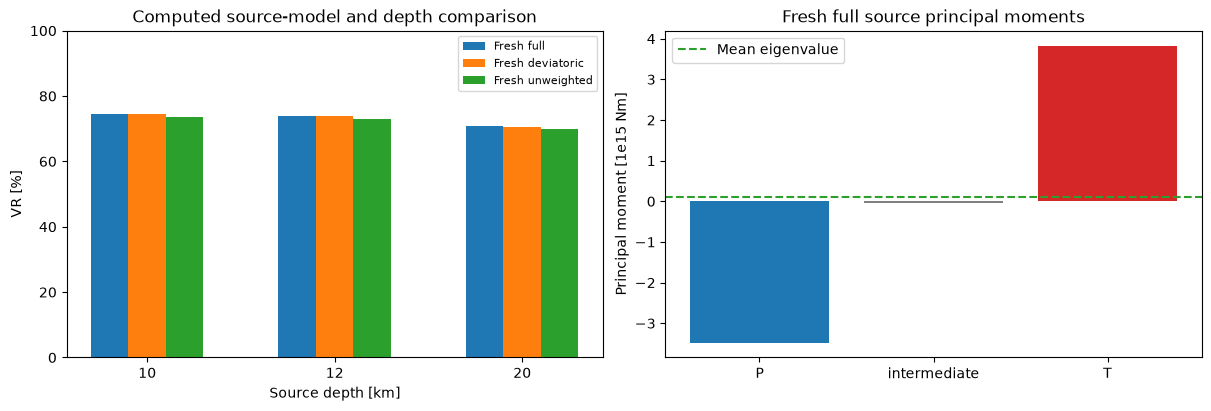

In [5]:
deviatoric=solve(data,degree=5)
unweighted=solve(data,weight='none')
def tensor_original(z,i):
    m=z[f'output_tensor{i}__m']*1e-7
    return np.array([[m[0],m[3],m[4]],[m[3],m[1],m[5]],[m[4],m[5],m[2]]])
comparison=[]
for i,depth in enumerate(fresh['depths']):
    comparison.append({'depth_km':float(depth),'fresh_full_VR':float(fresh['variance_reduction'][i]),'upstream_full_VR':float(original[f'output_tensor{i}_total_VR']),'full_relative_error':tensor_relative_error(fresh['tensors'][i],tensor_original(original,i)),'fresh_deviatoric_VR':float(deviatoric['variance_reduction'][i]),'upstream_deviatoric_VR':float(original_dev[f'output_tensor{i}_total_VR']),'deviatoric_relative_error':tensor_relative_error(deviatoric['tensors'][i],tensor_original(original_dev,i))})
display(Markdown('|Depth [km]|Fresh full VR [%]|Original full VR [%]|Full tensor relative error|Fresh deviatoric VR [%]|Original deviatoric VR [%]|\n|---|---|---|---|---|---|\n'+'\n'.join(f"|{r['depth_km']:.0f}|{r['fresh_full_VR']:.6f}|{r['upstream_full_VR']:.6f}|{r['full_relative_error']:.3g}|{r['fresh_deviatoric_VR']:.6f}|{r['upstream_deviatoric_VR']:.6f}|" for r in comparison)))
fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
x=np.arange(3);width=.2
for shift,values,label in [(-1,fresh['variance_reduction'],'Fresh full'),(0,deviatoric['variance_reduction'],'Fresh deviatoric'),(1,unweighted['variance_reduction'],'Fresh unweighted')]:axs[0].bar(x+shift*width,values,width,label=label)
axs[0].set_xticks(x,[f'{v:g}' for v in fresh['depths']]);axs[0].set(xlabel='Source depth [km]',ylabel='VR [%]',ylim=(0,100),title='Computed source-model and depth comparison');axs[0].legend(fontsize=8)
eigen=np.linalg.eigvalsh(tensor);isotropic=np.trace(tensor)/3*np.eye(3)
axs[1].bar(['P','intermediate','T'],eigen/1e15,color=['C0','grey','C3']);axs[1].axhline(np.trace(tensor)/3e15,color='C2',ls='--',label='Mean eigenvalue')
axs[1].set(ylabel='Principal moment [1e15 Nm]',title='Fresh full source principal moments');axs[1].legend()
plt.show()


## 5. Residuals and physics checks

Numerical method agreement does not remove Earth-model mismatch. Residual waveforms, station-wise explained energy and the weighted operator condition number indicate where the fixed model is incomplete. The adjoint identity checks that the local radiation transpose is consistent with the forward map. A pure isotropic source must produce zero transverse radiation, independently of the measured data.

No Gaussian measurement covariance was supplied. Consequently these residuals are not presented as calibrated chi-square statistics, and there is no claim that their magnitude is consistent with a known noise variance.

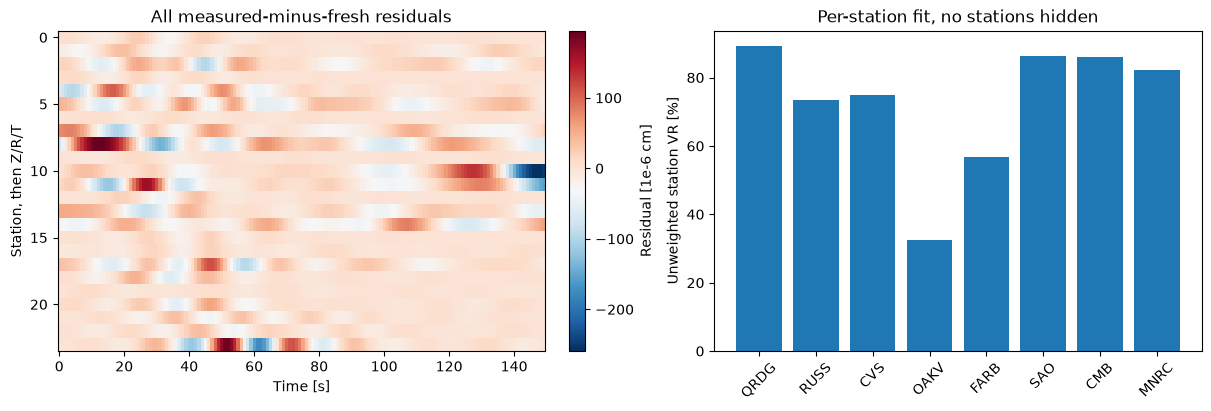

Adjoint relative discrepancy: 1.2516772080162422e-15
Isotropic transverse maximum [cm]: 0.0
Depth-specific normal-matrix condition: [39.6592316  25.61730007 23.46966405]


In [6]:
residual=observed-prediction
station_vr=100*(1-np.sum(residual**2,axis=(1,2))/np.sum(observed**2,axis=(1,2)))
fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
im=axs[0].imshow(residual.reshape(24,150)*1e6,aspect='auto',cmap='RdBu_r');fig.colorbar(im,ax=axs[0],label='Residual [1e-6 cm]')
axs[0].set(xlabel='Time [s]',ylabel='Station, then Z/R/T',title='All measured-minus-fresh residuals')
axs[1].bar(np.arange(8),station_vr);axs[1].set_xticks(np.arange(8),[s.split('.')[1] for s in STATIONS],rotation=45);axs[1].set(ylabel='Unweighted station VR [%]',title='Per-station fit, no stations hidden')
plt.show()
rng=np.random.default_rng(103);a=rng.normal(size=6);b=rng.normal(size=G.shape[0]);adjoint_error=abs(np.dot(G@a,b)-np.dot(a,G.T@b))/max(abs(np.dot(G@a,b)),1e-30)
isotropic_prediction=forward(data['fundamental_greens'][0],data['station_azimuth'],np.eye(3)*1e13)
print('Adjoint relative discrepancy:',adjoint_error)
print('Isotropic transverse maximum [cm]:',np.max(np.abs(isotropic_prediction[:,2])))
print('Depth-specific normal-matrix condition:',fresh['condition'])


## 6. Acquisition ablations, perturbation robustness and interpretation

Leave-one-station-out inversions quantify dependence on individual angular constraints. Separate noise experiments add independent zero-mean Gaussian perturbations with RMS equal to 1%, 5% or 10% of each station/component's observed RMS, then recompute every depth. These are controlled sensitivity experiments on real observations; they are not a calibrated data-generating model or confidence interval. The zero-noise result is also recomputed and shown, rather than filled with a placeholder.

The task answers a small but physical inverse question: which signed source tensor best explains this full regional acquisition under a fixed crustal calibration? It does not claim to image finite rupture geometry or validate the true isotropic fraction.

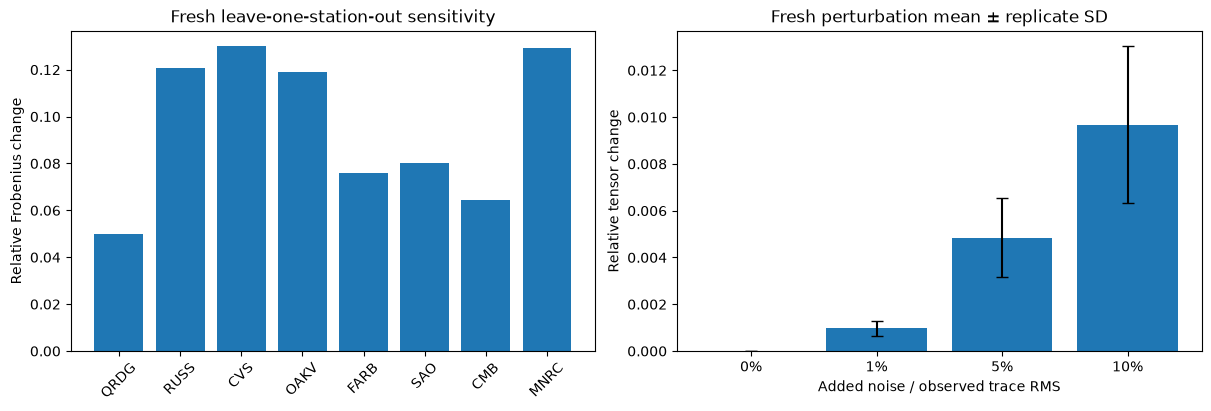

Total notebook compute seconds: 1.7259375999565236
All three full-tensor/deviatoric depth comparisons and sensitivity inversions above are freshly computed.


In [7]:
loo=[]
for omit in range(8):
    rr=solve(data,stations=np.delete(np.arange(8),omit))
    loo.append({'omitted':STATIONS[omit],'relative_change':tensor_relative_error(rr['reconstruction'][0],tensor),'depth_km':rr['source_depth'].item()})
noise_results=[];rms=np.sqrt(np.mean(data['waveforms'].astype(float)**2,axis=-1,keepdims=True))
for level in [0.,.01,.05,.1]:
    for replicate in range(8):
        perturbed={k:v.copy() for k,v in data.items()}
        perturbed['waveforms']=data['waveforms'].astype(float)+np.random.default_rng(4900+replicate).normal(size=data['waveforms'].shape)*rms*level
        rr=solve(perturbed)
        noise_results.append({'level':level,'replicate':replicate,'relative_change':tensor_relative_error(rr['reconstruction'][0],tensor),'depth_km':rr['source_depth'].item()})
fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axs[0].bar(np.arange(8),[x['relative_change'] for x in loo]);axs[0].set_xticks(np.arange(8),[s.split('.')[1] for s in STATIONS],rotation=45);axs[0].set(ylabel='Relative Frobenius change',title='Fresh leave-one-station-out sensitivity')
levels=[0.,.01,.05,.1];means=[];std=[]
for level in levels:
    v=[r['relative_change'] for r in noise_results if r['level']==level];means.append(np.mean(v));std.append(np.std(v))
axs[1].bar(np.arange(4),means,yerr=std,capsize=4);axs[1].set_xticks(np.arange(4),['0%','1%','5%','10%']);axs[1].set(xlabel='Added noise / observed trace RMS',ylabel='Relative tensor change',title='Fresh perturbation mean ± replicate SD')
plt.show()
summary={'runtime_s':runtime,'comparison':comparison,'station_VR':station_vr.tolist(),'leave_one_out':loo,'noise_sensitivity':noise_results,'adjoint_relative_error':adjoint_error,'notebook_compute_seconds':time.perf_counter()-started,'interpretation':'Method reference, not actual source truth; uncertainty plots are sensitivity studies.'}
Path('notebooks/reference_outputs/fresh_metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf-8')
print('Total notebook compute seconds:',summary['notebook_compute_seconds'])
print('All three full-tensor/deviatoric depth comparisons and sensitivity inversions above are freshly computed.')
